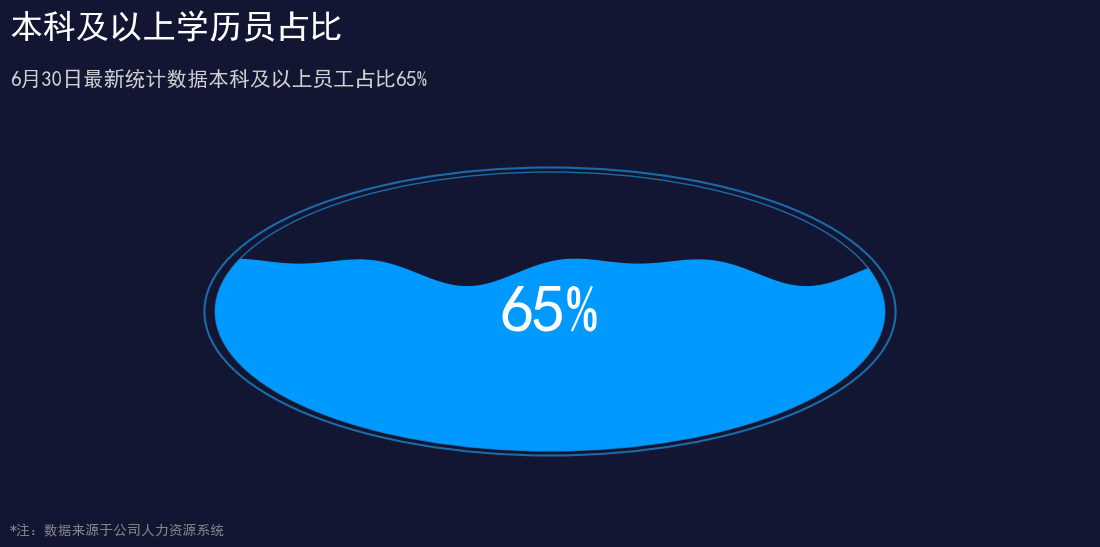

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import platform

system_name = platform.system()
if system_name == "Windows":
    plt.rcParams['font.sans-serif'] = ['SimHei']
elif system_name == "Darwin":
    plt.rcParams['font.sans-serif'] = ['Arial Unicode MS']
else:
    plt.rcParams['font.sans-serif'] = ['WenQuanYi Micro Hei']
plt.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(12, 6))

bg_color = '#121633'
text_color = '#ffffff'
circle_border_color = '#1a6ba8'
fill_color = '#0099ff'

fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

percentage = 65

center_x, center_y = 0.5, 0.43
radius = 0.32

outer_circle = patches.Circle((center_x, center_y), radius, facecolor='none', 
                               edgecolor=circle_border_color, linewidth=1.5)
ax.add_patch(outer_circle)

inner_circle = patches.Circle((center_x, center_y), radius - 0.01, facecolor='none', 
                               edgecolor=circle_border_color, linewidth=1)
ax.add_patch(inner_circle)

water_level = center_y - radius + (percentage / 100) * (2 * radius)

x_vals = np.linspace(center_x - radius, center_x + radius, 200)

wave1 = 0.025 * np.sin((x_vals - center_x) * 20)
wave2 = 0.015 * np.sin((x_vals - center_x) * 40 + 1.5)
wave_y = water_level + wave1 + wave2

fill_poly = ax.fill_between(x_vals, center_y - radius, wave_y, color=fill_color, zorder=3)

clip_circle = patches.Circle((center_x, center_y), radius - 0.01, facecolor='none', edgecolor='none')
ax.add_patch(clip_circle)

for collection in ax.collections:
    collection.set_clip_path(clip_circle)

ax.text(center_x, center_y, f'{percentage}%', ha='center', va='center', 
        color=text_color, fontsize=48, zorder=5)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis('off')

fig.text(0.05, 0.88, '本科及以上学历员占比',
         fontsize=24, fontweight='bold', color=text_color, ha='left')

fig.text(0.05, 0.80, '6月30日最新统计数据本科及以上员工占比65%',
         fontsize=15, color='#d0d0d0', ha='left')

fig.text(0.05, 0.05, '*注：数据来源于公司人力资源系统',
         fontsize=10, color='#888888', ha='left')

plt.subplots_adjust(top=0.85, bottom=0.1, left=0.05, right=0.95)

plt.show()

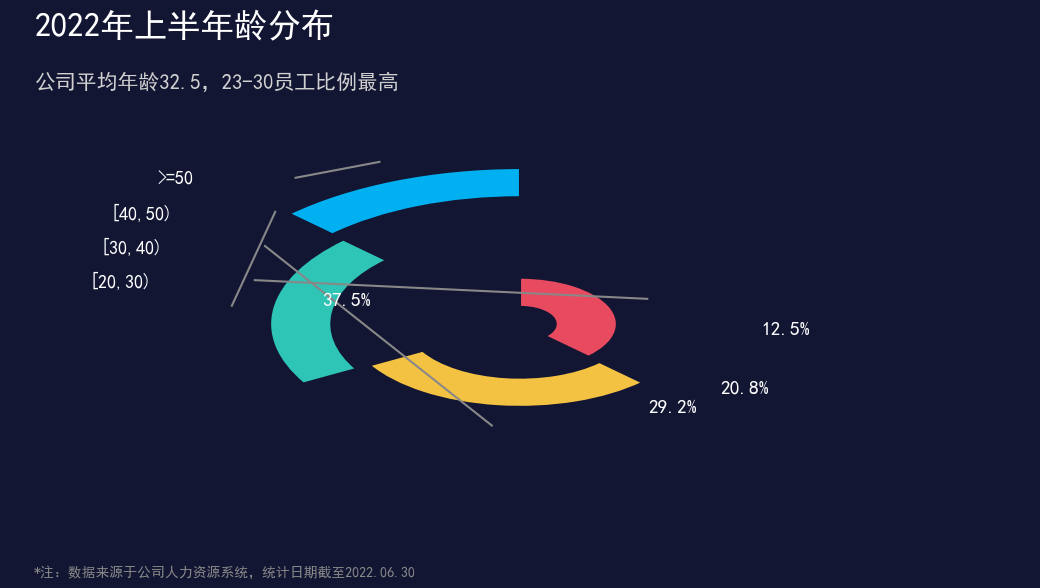

In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import platform

system_name = platform.system()
if system_name == "Windows":
    plt.rcParams['font.sans-serif'] = ['SimHei']
elif system_name == "Darwin":
    plt.rcParams['font.sans-serif'] = ['Arial Unicode MS']
else:
    plt.rcParams['font.sans-serif'] = ['WenQuanYi Micro Hei']
plt.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(12, 6.5))

bg_color = '#121633'
text_color = '#ffffff'

fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

center_x, center_y = 0.5, 0.45
radius_outer = 0.32
bar_width = 0.06

categories = ['>=50', '[40,50)', '[30,40)', '[20,30)']
values = [12.5, 20.8, 29.2, 37.5]
colors = ['#00b0f0', '#2ec4b6', '#f4c242', '#e84a5f']

start_angle = 90
total_angle = 360

for i, (val, color) in enumerate(zip(values, colors)):
    angle = (val / 100) * total_angle
    theta1 = start_angle
    theta2 = start_angle + angle
    
    current_radius = radius_outer - i * (bar_width + 0.015)
    
    wedge = patches.Wedge((center_x, center_y), current_radius, theta1, theta2, 
                          width=bar_width, facecolor=color, edgecolor=bg_color, linewidth=1.5)
    ax.add_patch(wedge)
    
    start_angle = theta2

label_positions = [
    (0.28, 0.75, 0.18, 0.75, '>=50'),
    (0.26, 0.68, 0.16, 0.68, '[40,50)'),
    (0.25, 0.61, 0.15, 0.61, '[30,40)'),
    (0.24, 0.54, 0.14, 0.54, '[20,30)')
]

for i, (x_line, y_line, x_text, y_text, label) in enumerate(label_positions):
    current_radius = radius_outer - i * (bar_width + 0.015)
    start_angle = 90 + sum([(values[j] / 100) * total_angle for j in range(i)])
    end_angle = start_angle + (values[i] / 100) * total_angle
    mid_angle = (start_angle + end_angle) / 2
    
    angle_rad = np.radians(mid_angle)
    x_start = center_x + (current_radius + bar_width/2 + 0.01) * np.cos(angle_rad)
    y_start = center_y + (current_radius + bar_width/2 + 0.01) * np.sin(angle_rad)
    
    ax.plot([x_start, x_line], [y_start, y_line], color='#888888', linewidth=1.5, zorder=10)
    ax.text(x_text, y_text, label, ha='right', va='center', color=text_color, fontsize=13, zorder=12)

value_positions = [
    (0.33, 0.50, '37.5%'),
    (0.65, 0.28, '29.2%'),
    (0.72, 0.32, '20.8%'),
    (0.76, 0.44, '12.5%')
]

for x, y, text in value_positions:
    ax.text(x, y, text, ha='center', va='center', color=text_color, fontsize=14, zorder=12)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis('off')

fig.text(0.12, 0.88, '2022年上半年龄分布',
         fontsize=24, fontweight='bold', color=text_color, ha='left')

fig.text(0.12, 0.80, '公司平均年龄32.5，23-30员工比例最高',
         fontsize=15, color='#d0d0d0', ha='left')

fig.text(0.12, 0.05, '*注：数据来源于公司人力资源系统，统计日期截至2022.06.30',
         fontsize=10, color='#888888', ha='left')

plt.subplots_adjust(top=0.85, bottom=0.1, left=0.1, right=0.95)

plt.show()

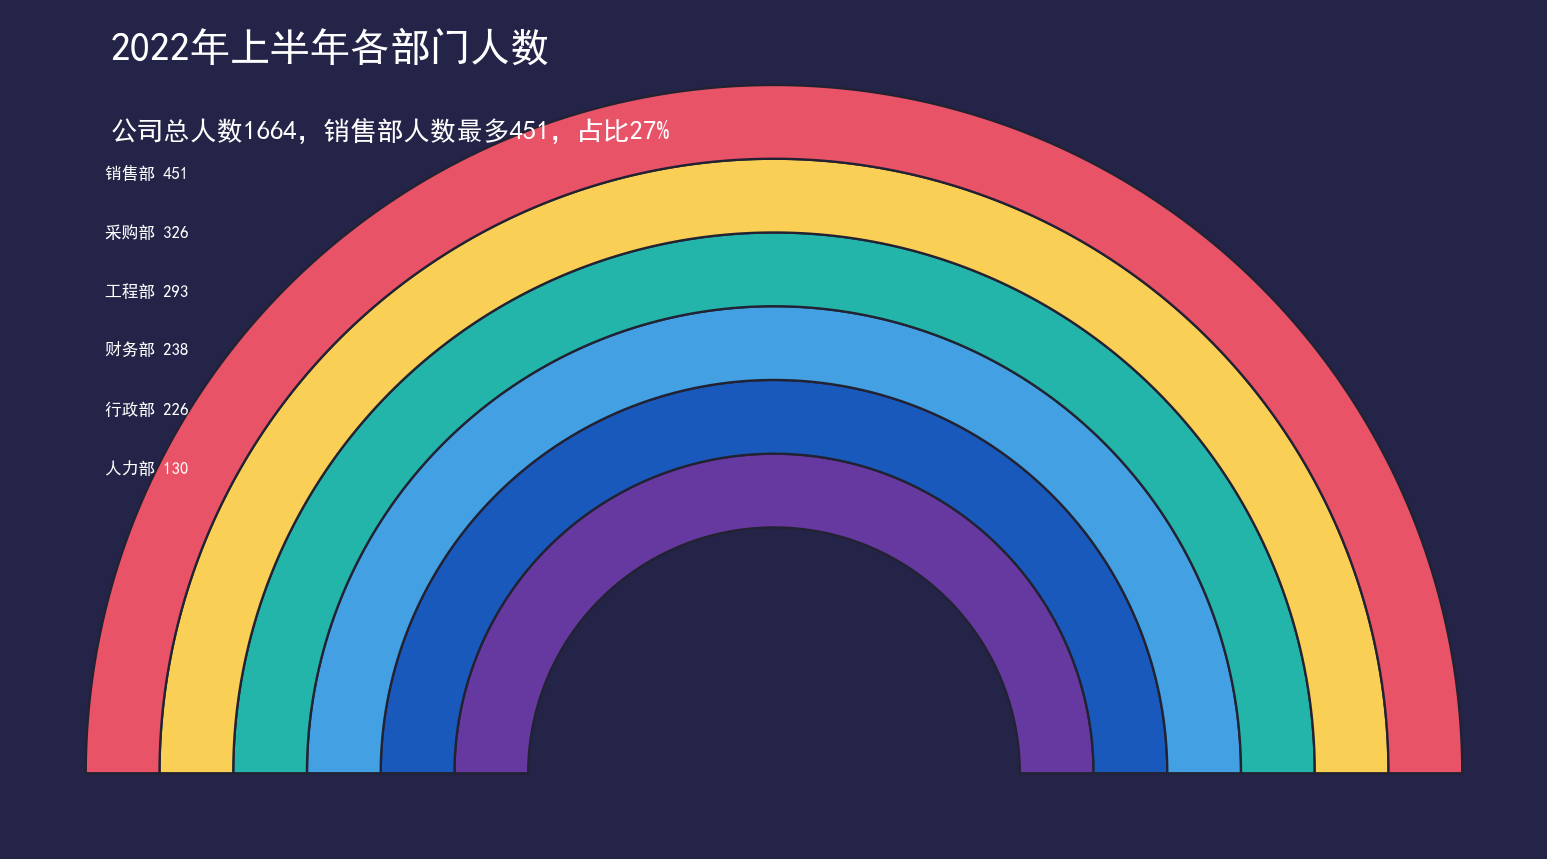

In [4]:
import matplotlib.pyplot as plt
import numpy as np

bg_color = "#242449"
text_color = "#ffffff"

dept_data = [
    {"name":"人力部","value":130,"color":"#6639a0","inner_r":1.0,"outer_r":1.3},
    {"name":"行政部","value":226,"color":"#1959bc","inner_r":1.3,"outer_r":1.6},
    {"name":"财务部","value":238,"color":"#43a0e2","inner_r":1.6,"outer_r":1.9},
    {"name":"工程部","value":293,"color":"#23b4aa","inner_r":1.9,"outer_r":2.2},
    {"name":"采购部","value":326,"color":"#f9d055","inner_r":2.2,"outer_r":2.5},
    {"name":"销售部","value":451,"color":"#e95368","inner_r":2.5,"outer_r":2.8}
]

fig, ax = plt.subplots(figsize=(13,8),dpi=120)
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)
ax.set_xlim(-3.1,3.1)
ax.set_ylim(-0.3,3.1)
ax.set_aspect("equal")
ax.axis("off")

theta = np.linspace(np.pi,0,300)
for d in dept_data:
    r_in = d["inner_r"]
    r_out = d["outer_r"]
    x_in = r_in * np.cos(theta)
    y_in = r_in * np.sin(theta)
    x_out = r_out * np.cos(theta)
    y_out = r_out * np.sin(theta)
    px = np.concatenate([x_in, np.flip(x_out)])
    py = np.concatenate([y_in, np.flip(y_out)])
    ax.fill(px,py,color=d["color"],edgecolor="#222233",linewidth=1.4)

text_list_left = [
    "销售部 451",
    "采购部 326",
    "工程部 293",
    "财务部 238",
    "行政部 226",
    "人力部 130"
]
y_start = 2.42
for s in text_list_left:
    ax.text(-2.72,y_start,s,color=text_color,fontsize=10)
    y_start -=0.24

ax.text(-2.70,2.90,"2022年上半年各部门人数",color=text_color,fontsize=24,weight='regular')
ax.text(-2.70,2.58,"公司总人数1664，销售部人数最多451，占比27%",color=text_color,fontsize=16)

plt.tight_layout()
plt.show()

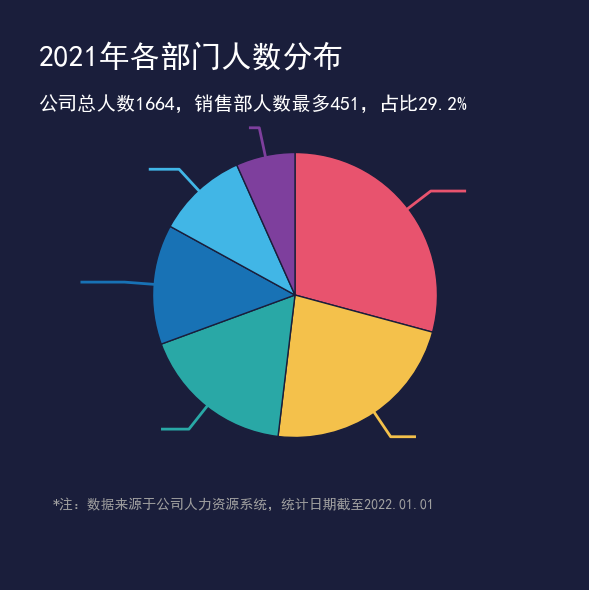

In [5]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

data = {
    '部门': ['销售部', '采购部', '工程部', '财务部', '行政部', '人力部'],
    '人数占比': [29.2, 22.7, 17.5, 13.6, 10.3, 6.7]
}
df = pd.DataFrame(data)

fig, ax = plt.subplots(figsize=(10, 6), facecolor='#1a1e3b')
ax.set_facecolor('#1a1e3b')

colors = ['#e8536e', '#f4c14b', '#29a8a6', '#1872b5', '#41b6e6', '#7e3f9d']

wedges, texts = ax.pie(
    df['人数占比'], 
    colors=colors, 
    startangle=90, 
    counterclock=False,
    wedgeprops={'linewidth': 1, 'edgecolor': '#1a1e3b'}
)

for i, wedge in enumerate(wedges):
    ang = (wedge.theta2 - wedge.theta1) / 2. + wedge.theta1
    y = plt.np.sin(plt.np.deg2rad(ang))
    x = plt.np.cos(plt.np.deg2rad(ang))
    
    if i == 0:
        line_x = [x * 0.8, x * 1.2, x * 1.5]
        line_y = [y * 0.8, y * 1.2, y * 1.2]
    else:
        line_x = [x * 0.8, x * 1.2, x * 1.5]
        line_y = [y * 0.8, y * 1.2, y * 1.2]
        
    ax.plot(line_x, line_y, color=colors[i], linewidth=2)
    ax.scatter(line_x[0], line_y[0], color=colors[i], s=15)

ax.text(-1.8, 1.6, '2021年各部门人数分布', fontsize=22, color='white', fontweight='bold')
ax.text(-1.8, 1.3, '公司总人数1664，销售部人数最多451，占比29.2%', fontsize=14, color='white')

ax.text(-1.7, -1.5, '*注：数据来源于公司人力资源系统，统计日期截至2022.01.01', fontsize=10, color='#a0a0a0')

ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.axis('off')

plt.tight_layout()
plt.show()

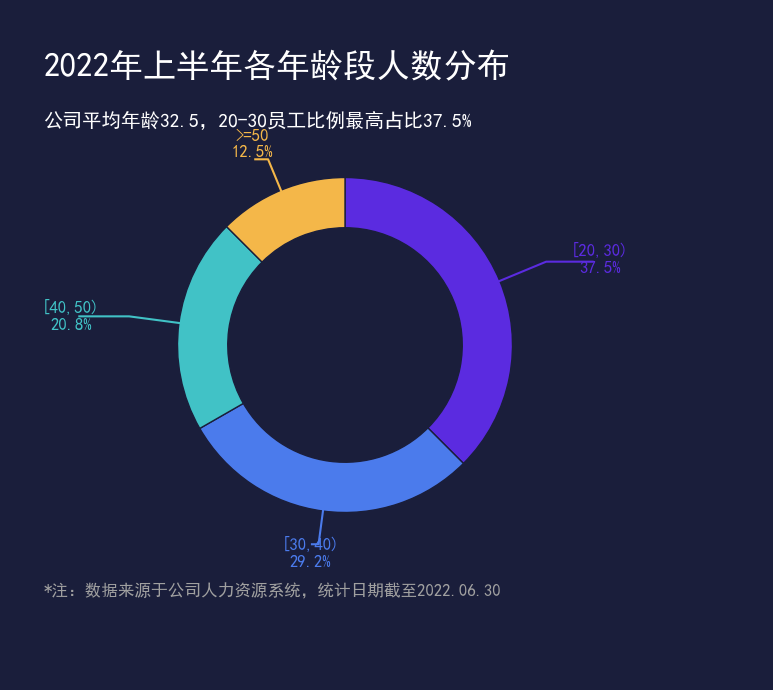

In [6]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

labels = ['[20,30)', '[30,40)', '[40,50)', '>=50']
sizes = [37.5, 29.2, 20.8, 12.5]
colors = ['#5b2be0', '#4b7bec', '#41c2c6', '#f4b749']

fig, ax = plt.subplots(figsize=(12, 7), facecolor='#1a1e3b')
ax.set_facecolor('#1a1e3b')

wedges, _ = ax.pie(
    sizes, 
    colors=colors, 
    startangle=90, 
    counterclock=False,
    wedgeprops={'width': 0.3, 'edgecolor': '#1a1e3b', 'linewidth': 1}
)

ax.text(-1.8, 1.6, '2022年上半年各年龄段人数分布', fontsize=24, color='white', fontweight='bold')
ax.text(-1.8, 1.3, '公司平均年龄32.5，20-30员工比例最高占比37.5%', fontsize=14, color='white')

for i, wedge in enumerate(wedges):
    ang = (wedge.theta2 + wedge.theta1) / 2.
    y = np.sin(np.deg2rad(ang))
    x = np.cos(np.deg2rad(ang))
    
    if i == 0:
        line_x = [x * 0.85, x * 1.3, x * 1.6]
        line_y = [y * 0.85, y * 1.3, y * 1.3]
        text_x, text_y = x * 1.65, y * 1.35
    elif i == 1:
        line_x = [x * 0.85, x * 1.2, x * 1.5]
        line_y = [y * 0.85, y * 1.2, y * 1.2]
        text_x, text_y = x * 1.55, y * 1.25
    elif i == 2:
        line_x = [x * 0.85, x * 1.3, x * 1.6]
        line_y = [y * 0.85, y * 1.3, y * 1.3]
        text_x, text_y = x * 1.65, y * 1.35
    else:
        line_x = [x * 0.85, x * 1.2, x * 1.4]
        line_y = [y * 0.85, y * 1.2, y * 1.2]
        text_x, text_y = x * 1.45, y * 1.3
        
    ax.plot(line_x, line_y, color=colors[i], linewidth=1.5)
    ax.scatter(line_x[0], line_y[0], color=colors[i], s=20)
    
    ax.text(text_x, text_y, f'{labels[i]}\n{sizes[i]}%', 
            color=colors[i], fontsize=12, ha='center', va='center')

ax.text(-1.8, -1.5, '*注：数据来源于公司人力资源系统，统计日期截至2022.06.30', fontsize=12, color='#a0a0a0')

ax.set_xlim(-2, 2.5)
ax.set_ylim(-2, 2)
ax.axis('off')

plt.tight_layout()
plt.show()

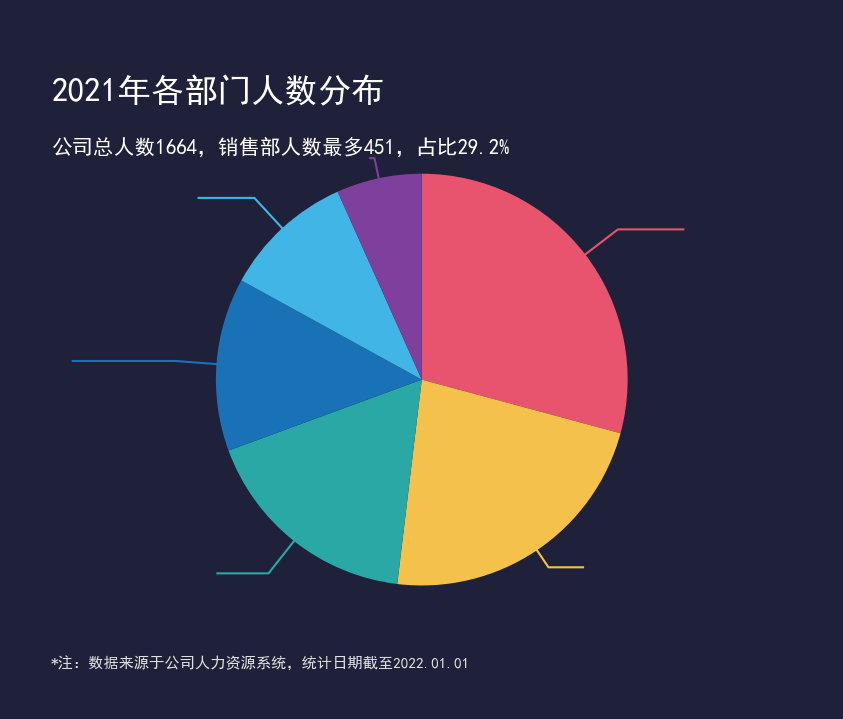

In [8]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(10, 7), facecolor='#1f2039')
ax.set_facecolor('#1f2039')

sizes = [29.2, 22.7, 17.5, 13.6, 10.3, 6.7]
colors = ['#e8536e', '#f4c14b', '#29a8a6', '#1872b5', '#41b6e6', '#7e3f9d']

wedges, _ = ax.pie(
    sizes, 
    colors=colors, 
    startangle=90, 
    counterclock=False,
    radius=1.0,
    wedgeprops={'linewidth': 0, 'edgecolor': 'none'}
)

for i, wedge in enumerate(wedges):
    ang = (wedge.theta2 + wedge.theta1) / 2.
    y = np.sin(np.deg2rad(ang))
    x = np.cos(np.deg2rad(ang))
    
    if i == 0:
        line_x = [x * 0.9, x * 1.2, x * 1.6]
        line_y = [y * 0.9, y * 1.2, y * 1.2]
        ax.plot(line_x, line_y, color=colors[i], linewidth=1.5)
        ax.scatter(line_x[0], line_y[0], color=colors[i], s=20, zorder=10)
    elif i == 1:
        line_x = [x * 0.9, x * 1.1, x * 1.4]
        line_y = [y * 0.9, y * 1.1, y * 1.1]
        ax.plot(line_x, line_y, color=colors[i], linewidth=1.5)
        ax.scatter(line_x[0], line_y[0], color=colors[i], s=20, zorder=10)
    elif i == 2:
        line_x = [x * 0.9, x * 1.2, x * 1.6]
        line_y = [y * 0.9, y * 1.2, y * 1.2]
        ax.plot(line_x, line_y, color=colors[i], linewidth=1.5)
        ax.scatter(line_x[0], line_y[0], color=colors[i], s=20, zorder=10)
    elif i == 3:
        line_x = [x * 0.9, x * 1.2, x * 1.7]
        line_y = [y * 0.9, y * 1.2, y * 1.2]
        ax.plot(line_x, line_y, color=colors[i], linewidth=1.5)
        ax.scatter(line_x[0], line_y[0], color=colors[i], s=20, zorder=10)
    elif i == 4:
        line_x = [x * 0.9, x * 1.2, x * 1.6]
        line_y = [y * 0.9, y * 1.2, y * 1.2]
        ax.plot(line_x, line_y, color=colors[i], linewidth=1.5)
        ax.scatter(line_x[0], line_y[0], color=colors[i], s=20, zorder=10)
    else:
        line_x = [x * 0.9, x * 1.1, x * 1.2]
        line_y = [y * 0.9, y * 1.1, y * 1.1]
        ax.plot(line_x, line_y, color=colors[i], linewidth=1.5)
        ax.scatter(line_x[0], line_y[0], color=colors[i], s=20, zorder=10)

ax.text(-1.8, 1.35, '2021年各部门人数分布', fontsize=24, color='white', fontweight='bold')
ax.text(-1.8, 1.1, '公司总人数1664，销售部人数最多451，占比29.2%', fontsize=15, color='white')
ax.text(-1.8, -1.4, '*注：数据来源于公司人力资源系统，统计日期截至2022.01.01', fontsize=11, color='#e0e0e0')

ax.set_xlim(-2, 2)
ax.set_ylim(-1.6, 1.8)
ax.axis('off')

plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
plt.show()

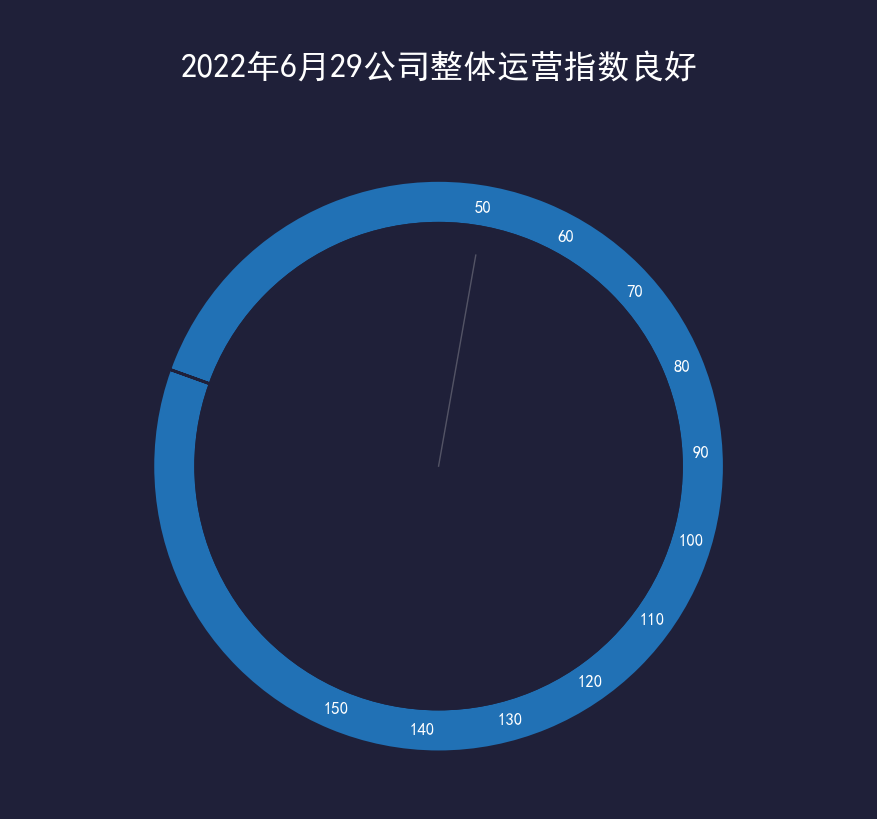

In [11]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(10, 8), facecolor='#1f2039')
ax.set_facecolor('#1f2039')

start_angle = 90
total_angle = 289.8

outer_colors = ['#f4b749'] * 3 + ['#2171b5'] * 6 + ['#e8536e'] * 2 + ['#2171b5'] * 4
inner_colors = ['#41c2c6'] * 3 + ['#1f2039'] * 12

for i in range(15):
    theta1 = start_angle - (i + 1) * (total_angle / 15)
    theta2 = start_angle - i * (total_angle / 15)
    
    ax.pie([1], radius=1.0, colors=[outer_colors[i]], startangle=theta1, counterclock=False,
           wedgeprops={'width': 0.15, 'edgecolor': '#1f2039', 'linewidth': 2})
    ax.pie([1], radius=0.85, colors=[inner_colors[i]], startangle=theta1, counterclock=False,
           wedgeprops={'width': 0.15, 'edgecolor': '#1f2039', 'linewidth': 2})

vals = [50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150]
for i, val in enumerate(vals):
    ang = start_angle - (i + 0.5) * (total_angle / 15)
    ang_rad = np.deg2rad(ang)
    x = 0.92 * np.cos(ang_rad)
    y = 0.92 * np.sin(ang_rad)
    ax.text(x, y, str(val), color='white', fontsize=12, ha='center', va='center')

ax.plot([0, 0.75 * np.cos(np.deg2rad(80))], [0, 0.75 * np.sin(np.deg2rad(80))], color='#cccccc', linewidth=1, alpha=0.3)

ax.text(0, 1.4, '2022年6月29公司整体运营指数良好', fontsize=24, color='white', fontweight='bold', ha='center', va='center')

ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.2, 1.6)
ax.axis('off')

plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
plt.show()

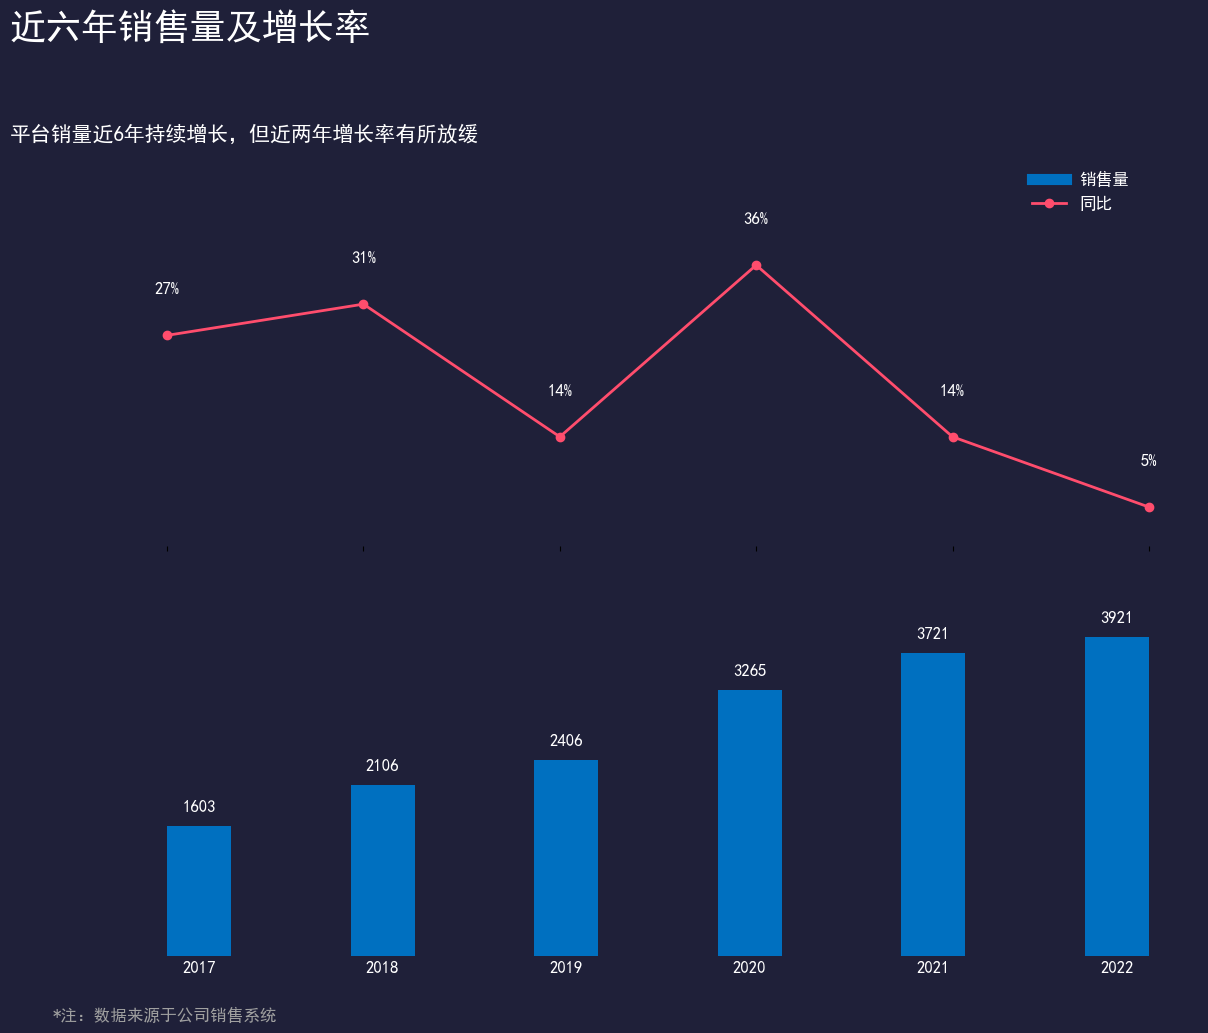

In [15]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

years = ['2017', '2018', '2019', '2020', '2021', '2022']
sales = [1603, 2106, 2406, 3265, 3721, 3921]
growth = [27, 31, 14, 36, 14, 5]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), facecolor='#1f2039', 
                              gridspec_kw={'height_ratios': [1, 1], 'hspace': 0.05})

ax1.set_facecolor('#1f2039')
ax2.set_facecolor('#1f2039')

x = np.arange(len(years))

ax1.plot(x, growth, color='#ff4d6d', marker='o', markersize=6, linewidth=2, zorder=4)
for i, v in enumerate(growth):
    ax1.text(i, v + 5, f'{v}%', color='white', fontsize=12, ha='center', va='bottom', zorder=5)

ax1.set_ylim(0, 50)
ax1.set_xticks(x)
ax1.set_xticklabels([])
ax1.set_yticks([])
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
ax1.spines['bottom'].set_visible(False)

bars = ax2.bar(x, sales, width=0.35, color='#0070c0', zorder=2)
for i, v in enumerate(sales):
    ax2.text(i, v + 150, str(v), color='white', fontsize=12, ha='center', va='bottom', zorder=3)

ax2.set_ylim(0, 4800)
ax2.set_xticks(x)
ax2.set_xticklabels(years, color='white', fontsize=12)
ax2.set_yticks([])
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['left'].set_visible(False)
ax2.spines['bottom'].set_visible(False)
ax2.tick_params(axis='x', colors='white', length=0)

ax1.text(-0.8, 65, '近六年销售量及增长率', fontsize=26, color='white', fontweight='bold')
ax1.text(-0.8, 52, '平台销量近6年持续增长，但近两年增长率有所放缓', fontsize=15, color='white')

ax2.text(-0.8, -800, '*注：数据来源于公司销售系统', fontsize=12, color='#a0a0a0')

legend_elements = [
    Line2D([0], [0], color='#0070c0', lw=8, label='销售量'),
    Line2D([0], [0], color='#ff4d6d', marker='o', lw=2, label='同比')
]
ax1.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(0.95, 1.0), 
           frameon=False, labelcolor='white', fontsize=12)

plt.subplots_adjust(left=0.05, right=0.95, top=0.9, bottom=0.1)
plt.show()

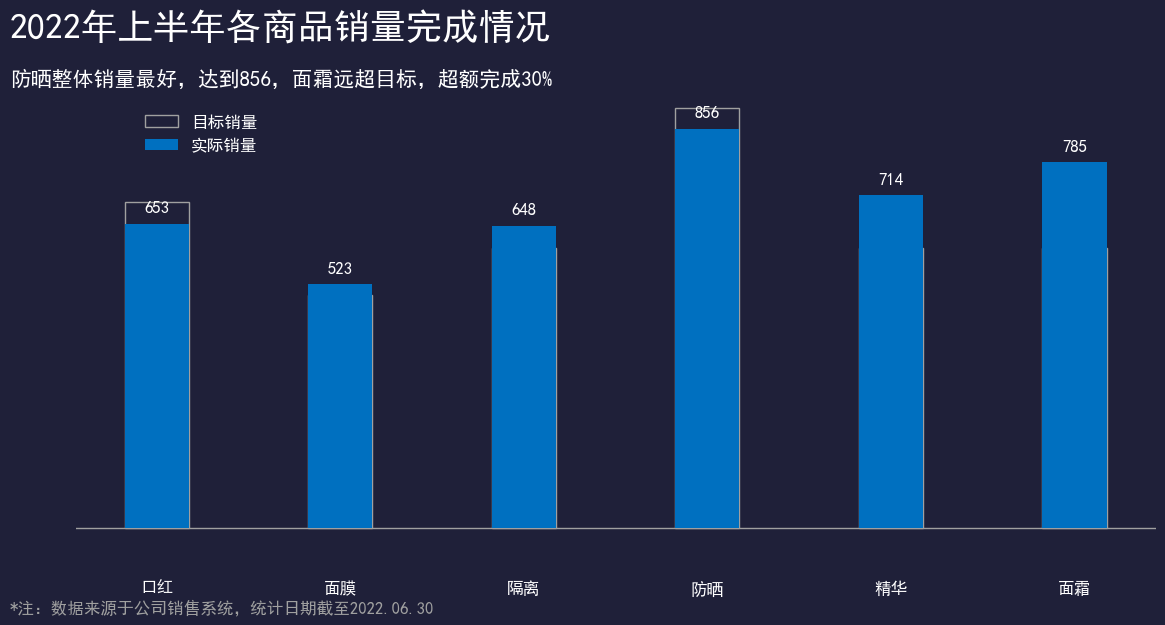

In [16]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

products = ['口红', '面膜', '隔离', '防晒', '精华', '面霜']
actual = [653, 523, 648, 856, 714, 785]
target = [700, 500, 600, 900, 600, 600]

fig, ax = plt.subplots(figsize=(12, 7), facecolor='#1f2039')
ax.set_facecolor('#1f2039')

x = np.arange(len(products))
width = 0.35

bars_target = ax.bar(x, target, width, color='#1f2039', edgecolor='#a0a0a0', linewidth=1, zorder=2)
bars_actual = ax.bar(x, actual, width, color='#0070c0', zorder=3)

for i, v in enumerate(actual):
    ax.text(i, v + 20, str(v), color='white', fontsize=12, ha='center', va='bottom', zorder=4)

ax.set_xticks(x)
ax.set_xticklabels(products, color='white', fontsize=12)
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(axis='x', colors='white', length=0)

ax.axhline(y=0, color='#a0a0a0', linewidth=1, zorder=1)

ax.text(-0.8, 1050, '2022年上半年各商品销量完成情况', fontsize=26, color='white', fontweight='bold')
ax.text(-0.8, 950, '防晒整体销量最好，达到856，面霜远超目标，超额完成30%', fontsize=15, color='white')

ax.text(-0.8, -180, '*注：数据来源于公司销售系统，统计日期截至2022.06.30', fontsize=12, color='#a0a0a0')

legend_elements = [
    Patch(facecolor='#1f2039', edgecolor='#a0a0a0', label='目标销量'),
    Patch(facecolor='#0070c0', label='实际销量')
]
ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(0.05, 0.85), 
          frameon=False, labelcolor='white', fontsize=12)

ax.set_ylim(-100, 1100)

plt.subplots_adjust(left=0.05, right=0.95, top=0.9, bottom=0.1)
plt.show()

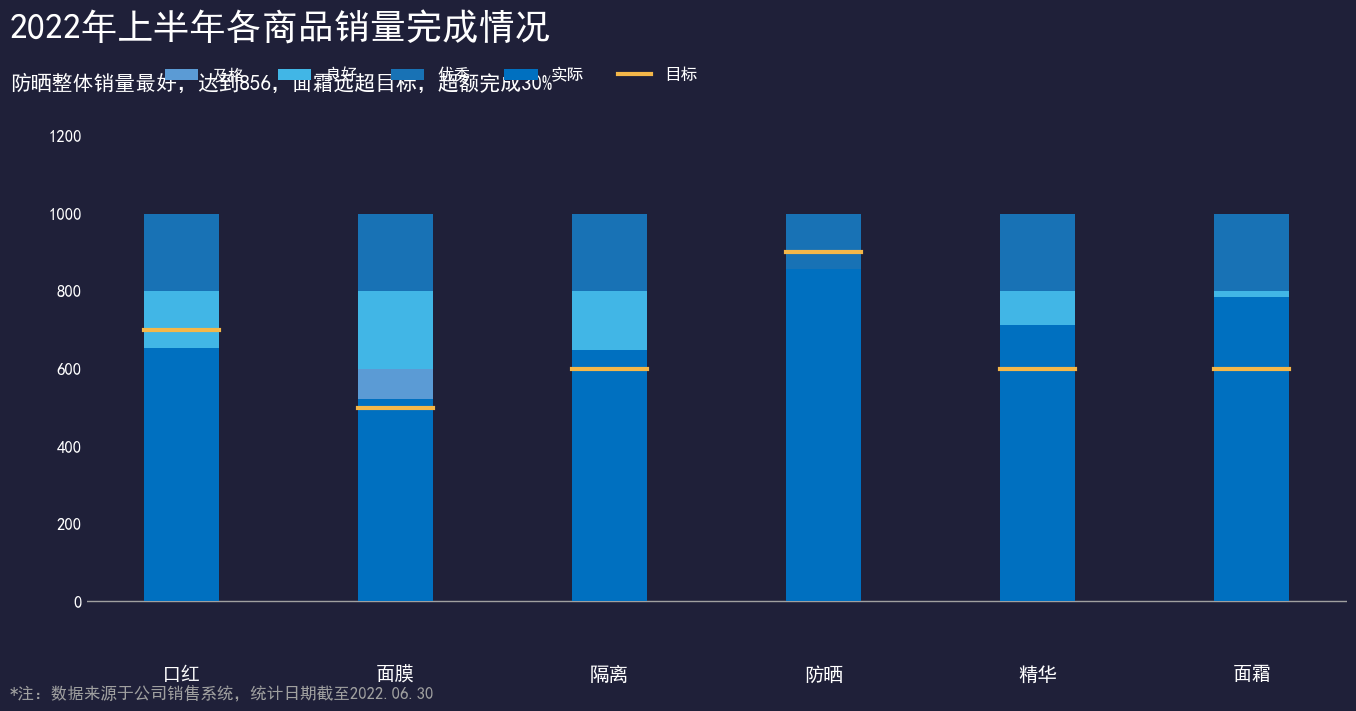

In [17]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

products = ['口红', '面膜', '隔离', '防晒', '精华', '面霜']
actual = [653, 523, 648, 856, 714, 785]
target = [700, 500, 600, 900, 600, 600]

qualified = [600, 600, 600, 600, 600, 600]
good = [200, 200, 200, 200, 200, 200]
excellent = [200, 200, 200, 200, 200, 200]

fig, ax = plt.subplots(figsize=(14, 8), facecolor='#1f2039')
ax.set_facecolor('#1f2039')

x = np.arange(len(products))
width = 0.35

ax.bar(x, qualified, width, color='#5b9bd5', zorder=2)
ax.bar(x, good, width, bottom=qualified, color='#41b6e6', zorder=2)
ax.bar(x, excellent, width, bottom=np.array(qualified)+np.array(good), color='#1872b5', zorder=2)

ax.bar(x, actual, width, color='#0070c0', zorder=3)

for i in range(len(products)):
    ax.plot([i - width/2, i + width/2], [target[i], target[i]], color='#f4b749', linewidth=3, zorder=4)

ax.set_xticks(x)
ax.set_xticklabels(products, color='white', fontsize=14)
ax.set_yticks([0, 200, 400, 600, 800, 1000, 1200])
ax.set_yticklabels(['0', '200', '400', '600', '800', '1000', '1200'], color='white', fontsize=12)

for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(axis='x', colors='white', length=0)
ax.tick_params(axis='y', colors='white', length=0)

ax.axhline(y=0, color='#a0a0a0', linewidth=1, zorder=1)

ax.text(-0.8, 1450, '2022年上半年各商品销量完成情况', fontsize=26, color='white', fontweight='bold')
ax.text(-0.8, 1320, '防晒整体销量最好，达到856，面霜远超目标，超额完成30%', fontsize=15, color='white')

ax.text(-0.8, -250, '*注：数据来源于公司销售系统，统计日期截至2022.06.30', fontsize=12, color='#a0a0a0')

legend_elements = [
    Patch(facecolor='#5b9bd5', label='及格'),
    Patch(facecolor='#41b6e6', label='良好'),
    Patch(facecolor='#1872b5', label='优秀'),
    Patch(facecolor='#0070c0', label='实际'),
    Line2D([0], [0], color='#f4b749', linewidth=3, label='目标')
]
ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(0.05, 0.95), 
          frameon=False, labelcolor='white', fontsize=12, ncol=5)

ax.set_ylim(-150, 1500)

plt.subplots_adjust(left=0.05, right=0.95, top=0.9, bottom=0.1)
plt.show()

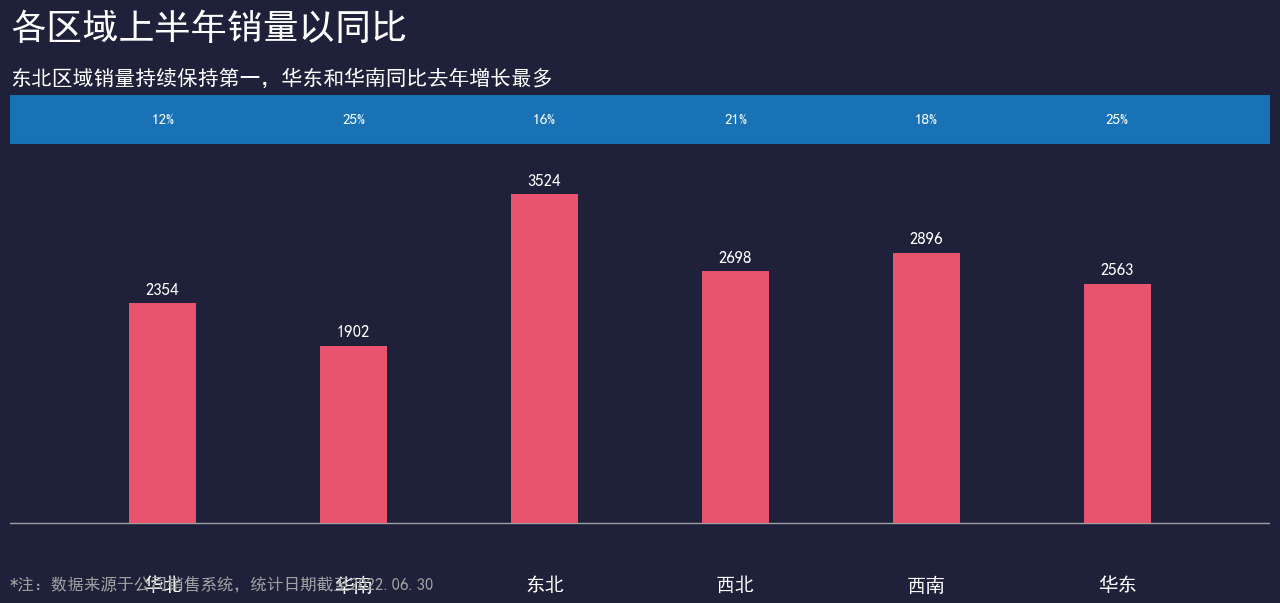

In [18]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

regions = ['华北', '华南', '东北', '西北', '西南', '华东']
sales = [2354, 1902, 3524, 2698, 2896, 2563]
growth = [12, 25, 16, 21, 18, 25]

fig, ax = plt.subplots(figsize=(14, 7), facecolor='#1f2039')
ax.set_facecolor('#1f2039')

x = np.arange(len(regions))
width = 0.35

bars = ax.bar(x, sales, width, color='#e8536e', zorder=2)

for i, v in enumerate(sales):
    ax.text(i, v + 80, str(v), color='white', fontsize=12, ha='center', va='bottom', zorder=3)

max_sales = max(sales)
circle_y = max_sales + 800

for i, v in enumerate(growth):
    circle = plt.Circle((i, circle_y), radius=250, color='#1872b5', zorder=3)
    ax.add_patch(circle)
    ax.text(i, circle_y, f'{v}%', color='white', fontsize=11, ha='center', va='center', zorder=4)

ax.set_xticks(x)
ax.set_xticklabels(regions, color='white', fontsize=14)
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(axis='x', colors='white', length=0)

ax.axhline(y=0, color='#a0a0a0', linewidth=1, zorder=1)

ax.text(-0.8, 5200, '各区域上半年销量以同比', fontsize=26, color='white', fontweight='bold')
ax.text(-0.8, 4700, '东北区域销量持续保持第一，华东和华南同比去年增长最多', fontsize=15, color='white')

ax.text(-0.8, -700, '*注：数据来源于公司销售系统，统计日期截至2022.06.30', fontsize=12, color='#a0a0a0')

ax.set_ylim(-500, 5500)
ax.set_xlim(-0.8, len(regions) - 0.2)

plt.subplots_adjust(left=0.05, right=0.95, top=0.9, bottom=0.1)
plt.show()

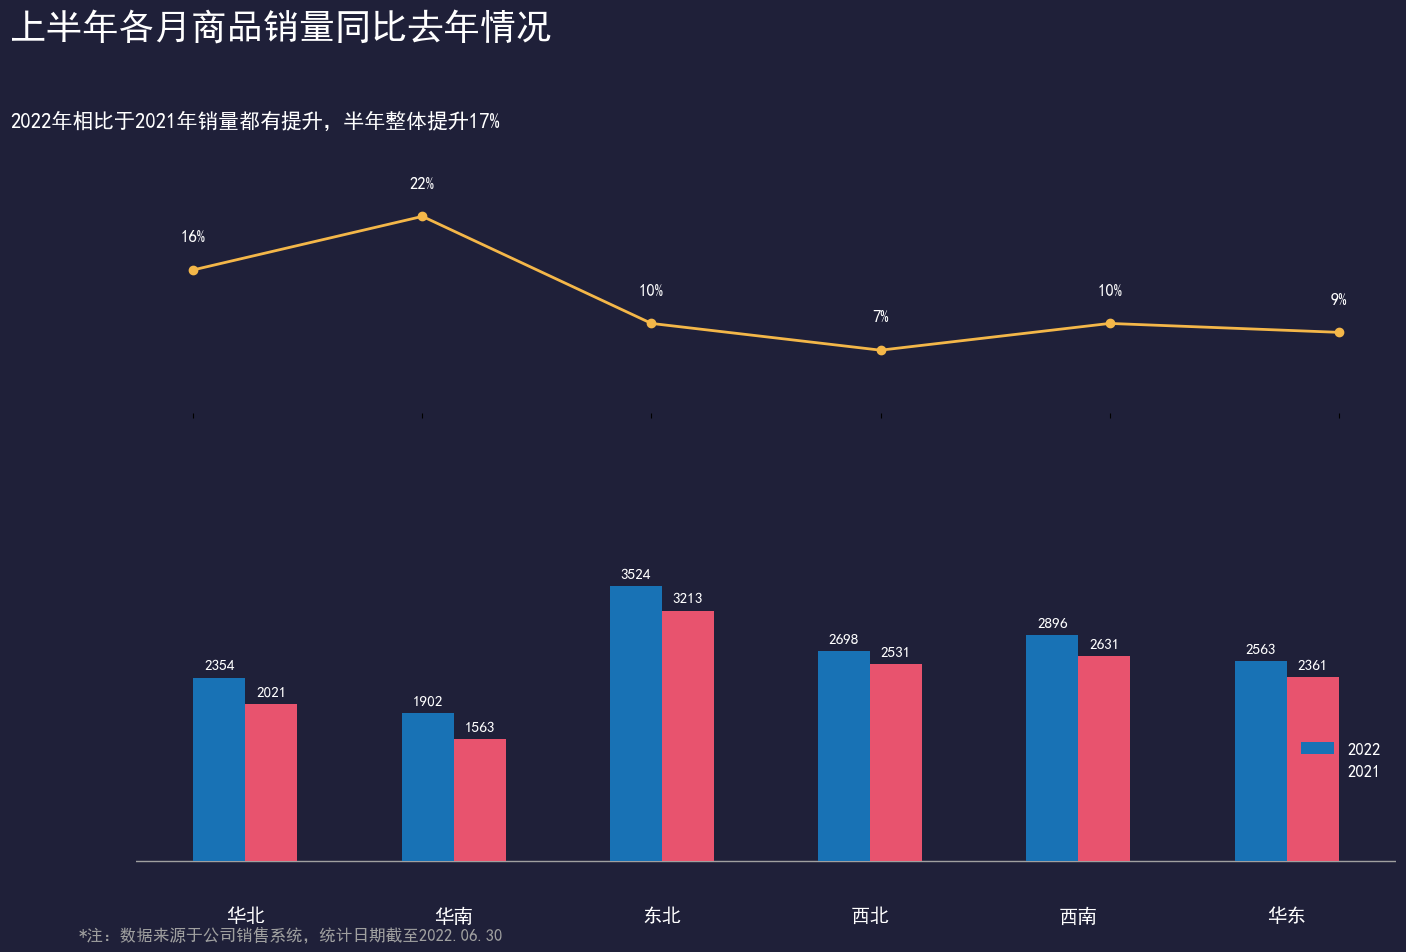

In [20]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

regions = ['华北', '华南', '东北', '西北', '西南', '华东']
sales_2022 = [2354, 1902, 3524, 2698, 2896, 2563]
sales_2021 = [2021, 1563, 3213, 2531, 2631, 2361]
growth = [16, 22, 10, 7, 10, 9]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), facecolor='#1f2039', 
                              gridspec_kw={'height_ratios': [1, 1.5], 'hspace': 0.05})

ax1.set_facecolor('#1f2039')
ax2.set_facecolor('#1f2039')

x = np.arange(len(regions))
width = 0.25

ax1.plot(x, growth, color='#f4b749', marker='o', markersize=6, linewidth=2, zorder=4)
for i, v in enumerate(growth):
    ax1.text(i, v + 3, f'{v}%', color='white', fontsize=12, ha='center', va='bottom', zorder=5)

ax1.set_ylim(0, 35)
ax1.set_xticks(x)
ax1.set_xticklabels([])
ax1.set_yticks([])
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
ax1.spines['bottom'].set_visible(False)

bars1 = ax2.bar(x - width/2, sales_2022, width, color='#1872b5', zorder=2)
bars2 = ax2.bar(x + width/2, sales_2021, width, color='#e8536e', zorder=2)

for i in range(len(regions)):
    ax2.text(i - width/2, sales_2022[i] + 80, str(sales_2022[i]), color='white', fontsize=11, ha='center', va='bottom', zorder=3)
    ax2.text(i + width/2, sales_2021[i] + 80, str(sales_2021[i]), color='white', fontsize=11, ha='center', va='bottom', zorder=3)

ax2.set_xticks(x)
ax2.set_xticklabels(regions, color='white', fontsize=14)
ax2.set_yticks([])
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['left'].set_visible(False)
ax2.spines['bottom'].set_visible(False)
ax2.tick_params(axis='x', colors='white', length=0)

ax2.axhline(y=0, color='#a0a0a0', linewidth=1, zorder=1)

ax1.text(-0.8, 42, '上半年各月商品销量同比去年情况', fontsize=26, color='white', fontweight='bold')
ax1.text(-0.8, 32, '2022年相比于2021年销量都有提升，半年整体提升17%', fontsize=15, color='white')

ax2.text(-0.8, -1000, '*注：数据来源于公司销售系统，统计日期截至2022.06.30', fontsize=12, color='#a0a0a0')

legend_elements = [
    Patch(facecolor='#1872b5', label='2022'),
    Patch(facecolor='#e8536e', label='2021')
]
ax2.legend(handles=legend_elements, loc='center right', bbox_to_anchor=(1.0, 0.3), 
          frameon=False, labelcolor='white', fontsize=12)

ax2.set_ylim(-500, 5500)

plt.subplots_adjust(left=0.05, right=0.95, top=0.9, bottom=0.1)
plt.show()

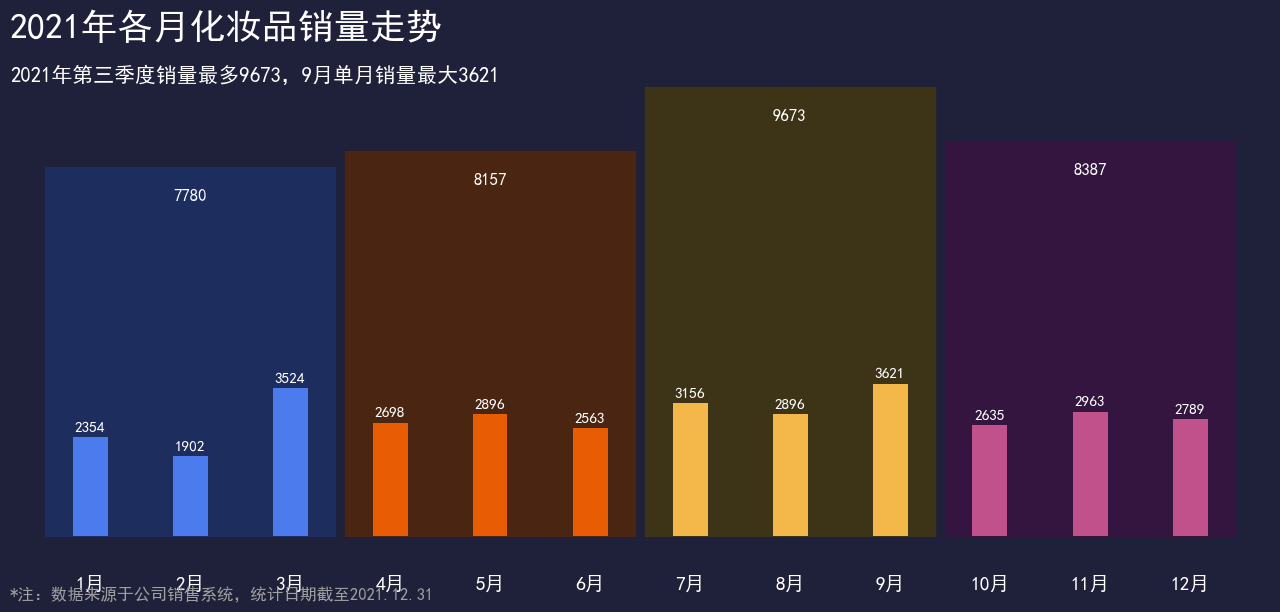

In [21]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

months = ['1月', '2月', '3月', '4月', '5月', '6月', '7月', '8月', '9月', '10月', '11月', '12月']
monthly_sales = [2354, 1902, 3524, 2698, 2896, 2563, 3156, 2896, 3621, 2635, 2963, 2789]
quarterly_sales = [7780, 7780, 7780, 8157, 8157, 8157, 9673, 9673, 9673, 8387, 8387, 8387]
quarterly_labels = ['7780', '8157', '9673', '8387']

fig, ax = plt.subplots(figsize=(14, 7), facecolor='#1f2039')
ax.set_facecolor('#1f2039')

x = np.arange(len(months))
width = 0.35

bar_colors = ['#4b7bec', '#4b7bec', '#4b7bec', 
              '#e85d04', '#e85d04', '#e85d04', 
              '#f4b749', '#f4b749', '#f4b749', 
              '#c0518a', '#c0518a', '#c0518a']

bars = ax.bar(x, monthly_sales, width, color=bar_colors, zorder=3)

for i, v in enumerate(monthly_sales):
    ax.text(i, v + 80, str(v), color='white', fontsize=11, ha='center', va='bottom', zorder=4)

bg_colors = ['#1c2d5e', '#1c2d5e', '#1c2d5e', 
             '#4a2511', '#4a2511', '#4a2511', 
             '#3d3418', '#3d3418', '#3d3418', 
             '#331540', '#331540', '#331540']

for i in range(4):
    start_idx = i * 3
    end_idx = start_idx + 3
    bg_rect = plt.Rectangle((start_idx - 0.45, 0), 3 - 0.1, quarterly_sales[start_idx] + 1000, 
                            color=bg_colors[start_idx], zorder=1)
    ax.add_patch(bg_rect)
    ax.text(start_idx + 1, quarterly_sales[start_idx] + 150, quarterly_labels[i], 
            color='white', fontsize=12, ha='center', va='bottom', zorder=4)

ax.set_xticks(x)
ax.set_xticklabels(months, color='white', fontsize=14)
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(axis='x', colors='white', length=0)

ax.text(-0.8, 11800, '2021年各月化妆品销量走势', fontsize=26, color='white', fontweight='bold')
ax.text(-0.8, 10800, '2021年第三季度销量最多9673，9月单月销量最大3621', fontsize=15, color='white')

ax.text(-0.8, -1500, '*注：数据来源于公司销售系统，统计日期截至2021.12.31', fontsize=12, color='#a0a0a0')

ax.set_ylim(-800, 12500)
ax.set_xlim(-0.8, 11.8)

plt.subplots_adjust(left=0.05, right=0.95, top=0.9, bottom=0.1)
plt.show()

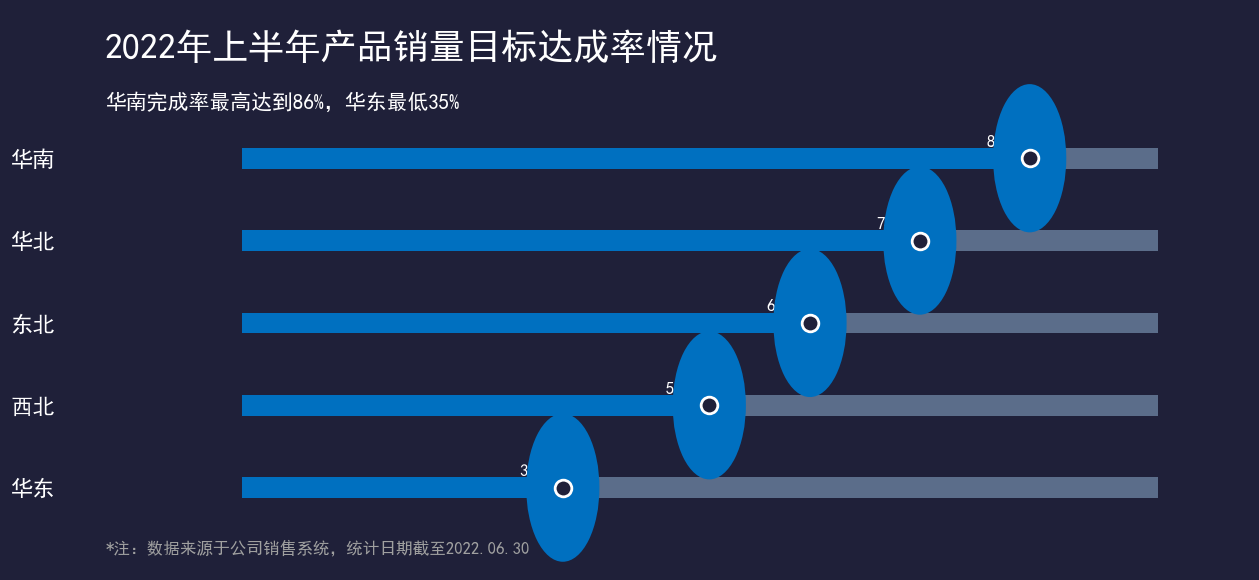

In [23]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

regions = ['华东', '西北', '东北', '华北', '华南']
completion_rates = [35, 51, 62, 74, 86]

fig, ax = plt.subplots(figsize=(14, 7), facecolor='#1f2039')
ax.set_facecolor('#1f2039')

y_pos = np.arange(len(regions))

ax.barh(y_pos, [100]*len(regions), height=0.25, color='#5b6d8a', zorder=2)
ax.barh(y_pos, completion_rates, height=0.25, color='#0070c0', zorder=3)

for i, v in enumerate(completion_rates):
    ax.text(v - 2, i + 0.2, f'{v}%', color='white', fontsize=12, ha='right', va='center', zorder=4)
    
    ellipse = plt.matplotlib.patches.Ellipse((v, i), width=8, height=1.8, 
                                             facecolor='#0070c0', edgecolor='none', zorder=4)
    ax.add_patch(ellipse)
    
    ax.plot(v, i, marker='o', markersize=12, markerfacecolor='#1f2039', 
            markeredgecolor='white', markeredgewidth=2, zorder=6)

ax.set_yticks(y_pos)
ax.set_yticklabels(regions, color='white', fontsize=16)
ax.set_xticks([])

for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(axis='y', colors='white', length=0)

ax.text(-15, 5.2, '2022年上半年产品销量目标达成率情况', fontsize=26, color='white', fontweight='bold')
ax.text(-15, 4.6, '华南完成率最高达到86%，华东最低35%', fontsize=15, color='white')

ax.text(-15, -0.8, '*注：数据来源于公司销售系统，统计日期截至2022.06.30', fontsize=12, color='#a0a0a0')

ax.set_xlim(-20, 110)
ax.set_ylim(-1, 5.8)

plt.subplots_adjust(left=0.1, right=0.95, top=0.9, bottom=0.1)
plt.show()

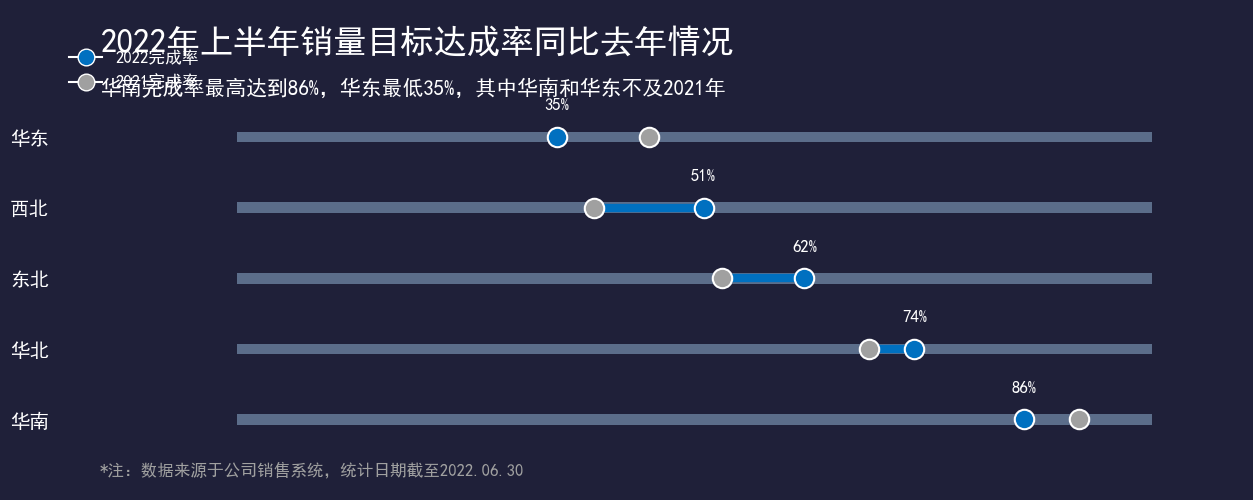

In [24]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

regions = ['华南', '华北', '东北', '西北', '华东']
rate_2022 = [86, 74, 62, 51, 35]
rate_2021 = [92, 69, 53, 39, 45]

fig, ax = plt.subplots(figsize=(14, 6), facecolor='#1f2039')
ax.set_facecolor('#1f2039')

y_pos = np.arange(len(regions))

ax.barh(y_pos, [100]*len(regions), height=0.15, color='#5b6d8a', zorder=2)

for i in range(len(regions)):
    if rate_2022[i] >= rate_2021[i]:
        ax.plot([rate_2021[i], rate_2022[i]], [i, i], color='#0070c0', linewidth=6, zorder=3)
        ax.plot(rate_2022[i], i, marker='o', markersize=14, markerfacecolor='#0070c0', 
                markeredgecolor='white', markeredgewidth=1.5, zorder=5)
        ax.plot(rate_2021[i], i, marker='o', markersize=14, markerfacecolor='#a0a0a0', 
                markeredgecolor='white', markeredgewidth=1.5, zorder=4)
        ax.text(rate_2022[i], i + 0.35, f'{rate_2022[i]}%', color='white', fontsize=12, ha='center', va='bottom', zorder=6)
    else:
        ax.plot([rate_2022[i], rate_2021[i]], [i, i], color='#5b6d8a', linewidth=6, zorder=3)
        ax.plot(rate_2022[i], i, marker='o', markersize=14, markerfacecolor='#0070c0', 
                markeredgecolor='white', markeredgewidth=1.5, zorder=5)
        ax.plot(rate_2021[i], i, marker='o', markersize=14, markerfacecolor='#a0a0a0', 
                markeredgecolor='white', markeredgewidth=1.5, zorder=4)
        ax.text(rate_2022[i], i + 0.35, f'{rate_2022[i]}%', color='white', fontsize=12, ha='center', va='bottom', zorder=6)

ax.set_yticks(y_pos)
ax.set_yticklabels(regions, color='white', fontsize=14)
ax.set_xticks([])

for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(axis='y', colors='white', length=0)

ax.text(-15, 5.2, '2022年上半年销量目标达成率同比去年情况', fontsize=24, color='white', fontweight='bold')
ax.text(-15, 4.6, '华南完成率最高达到86%，华东最低35%，其中华南和华东不及2021年', fontsize=15, color='white')

ax.text(-15, -0.8, '*注：数据来源于公司销售系统，统计日期截至2022.06.30', fontsize=12, color='#a0a0a0')

legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#0070c0', markersize=12, label='2022完成率'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#a0a0a0', markersize=12, label='2021完成率')
]
ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(0.0, 0.95), 
          frameon=False, labelcolor='white', fontsize=12)

ax.set_xlim(-20, 110)
ax.set_ylim(-1, 5.8)

plt.subplots_adjust(left=0.1, right=0.95, top=0.9, bottom=0.1)
plt.show()